# CausalBridges-09 — Emuler un essai ciblé : confounding variant dans le temps (Hernan/Robins)

[← Série Causal-Bridges](README.md) | [CB-08 Fairness ←](CausalBridges-08-Causal-Fairness.ipynb)

**Ce carnet est le pli 2 de l'extension Origami de la série** (EPIC [#19309](https://github.com/jsboige/CoursIA/issues/19309)) : il traite le premier angle mort mesuré par le scan causal du dépôt — **la dimension temporelle** d'un traitement administré sur plusieurs visites, là où les confondeurs eux-mêmes changent au cours du suivi.

L'idée centrale de la *target trial emulation* (Hernan & Robins, [*Causal Inference: What If*](https://www.hsph.harvard.edu/miguel-hernan/causal-inference-book/), ch. 21-22) : une étude observationnelle ne vaut que par l'**essai randomisé qu'elle émule**. On écrit d'abord le protocole de l'essai ciblé — éligibilité, stratégies de traitement, assignment, suivi, outcome, contraste causal — puis on rapproche l'analyse observationnelle de ce protocole. Sur données longitudinales, l'ajustement naïf échoue : ajuster sur un confondeur **mesuré après le début du traitement**, c'est ajuster sur un médiateur. Il faut des **g-méthodes** : g-formula (Robins 1986) et IPTW longitudinal (Robins 1999).

## Objectifs d'apprentissage

A l'issue de ce carnet, le lecteur est capable de :

1. **Spécifier un essai ciblé** (7 composantes du protocole) et le reconnaître comme la boussole de l'analyse observationnelle.
2. **Diagnostiquer le confounding variant dans le temps** sur un DAG à visites $t = 0, 1$ : pourquoi $L_1$ est à la fois confondeur (pour $A_1 \to Y$) et médiateur (de $A_0 \to Y$).
3. **Implémenter la g-formula paramétrique** par Monte-Carlo : fit des modèles de résultat et d'évolution, simulation forward sous deux stratégies.
4. **Implémenter l'IPTW longitudinal** avec poids stabilisés et pondération de censuration.
5. **Lire un tableau de biais / RMSE / couverture** sur 200 répliques, et nommer le gagnant **selon la force du confounding** — pas en absolu.

## Navigation

1. **Motivation** : le cas LBP (lombalgie récurrente) — pourquoi l'observation seule est piégée
2. **Le DAG à deux visites** : $L_0 \to A_0 \to L_1 \to A_1 \to Y$ avec censuration $C$
3. **Les estimateurs naïfs** : non-ajusté, ajusté baseline, ajusté complet (le pire des trois)
4. **dowhy sur l'instantané $t=0$** : ce que l'organe SOTA identifie — et pourquoi il s'arrête là
5. **G-formula** (Robins 1986) : standardisation par simulation forward
6. **IPTW longitudinal** (Robins 1999) : poids stabilisés + censuration
7. **L'essai émulé** : le protocole complet, composante par composante
8. **Benchmark 200 répliques** : biais, RMSE, couverture IC 95 %, deux forces de confounding
9. **Verdict** : quel estimateur gagne, et quand
10. **Exercices** (5) et bibliographie

## 1. Motivation — la lombalgie récurrente comme essai ciblé

**Exemple canonique** (variante pédagogique de Hernan ch. 21) : des patients souffrant de lombalgie récurrente (LBP, *low back pain*) consultent à deux visites. À chaque visite, le praticien **switch** vers kinésithérapie renforcée ($A_t = 1$) ou maintient le traitement standard ($A_t = 0$) en fonction de la douleur $L_t$ mesurée ce jour. L'outcome $Y$ est le score d'incapacité fonctionnelle en fin de suivi (plus haut = plus invalidé).

Le piège : la douleur $L_1$ de la visite 1 **est causée par** le traitement $A_0$ et **cause** à la fois le traitement $A_1$ et l'outcome $Y$. Un praticien observe « les patients switchés deux fois vont moins bien » — est-ce l'effet du switch, ou le fait qu'on ne switche que les patients qui souffrent, c'est-à-dire ceux qui allaient moins bien de toute façon ?

La réponse de Hernan : écrire d'abord **l'essai randomisé qu'on aurait voulu faire** —

| Composante du protocole | Essai ciblé émulé |
|---|---|
| Critères d'éligibilité | Lombalgie récurrente diagnostiquée, visite $t=0$ |
| Stratégies de traitement | (a) *switch immédiat aux deux visites* vs (b) *standard aux deux visites* |
| Assignment | Randomisé (émulé par pondération/standardisation) |
| Suivi | Deux visites, outcome mesuré à la fin |
| Outcome | Score d'incapacité $Y$ |
| Contraste causal | $E[Y^{\text{switch, switch}} - Y^{\text{standard, standard}}]$ |
| Analyse | Intention de traiter sur les stratégies, g-méthodes pour l'émuler |

— puis demander : **quelle méthode d'analyse rapproche mes données observationnelles de CE protocole ?** C'est ce que les cellules suivantes mesurent.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

# ------------------------------------------------------------------
# DGP semi-synthetique : lombalgie recurrente, deux visites.
# gamma = force du confounding (L_t -> A_t). On la fera varier.
# ------------------------------------------------------------------
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def simulate_lbp(n, gamma, rng, strategy="observe"):
    """Genere (L0, A0, L1, A1, C, Y_obs, Y).

    strategy:
      'observe' : A_t decide par le praticier selon L_t (donnees reelles)
      'always'  : A_0 = A_1 = 1 (essai: switch aux deux visites)
      'never'   : A_0 = A_1 = 0 (essai: standard aux deux visites)
    """
    L0 = rng.normal(0.0, 1.0, n)
    if strategy == "observe":
        A0 = (rng.uniform(size=n) < sigmoid(-0.5 + gamma * L0)).astype(float)
    else:
        A0 = np.full(n, 1.0 if strategy == "always" else 0.0)
    L1 = 0.6 * L0 - 0.8 * A0 + rng.normal(0.0, 0.8, n)
    if strategy == "observe":
        A1 = (rng.uniform(size=n) < sigmoid(-0.5 + gamma * L1)).astype(float)
    else:
        A1 = A0.copy()  # strategies constantes sur les deux visites
    # Outcome structurel (interaction A0 x L1 : la verite n'est pas analytique)
    Y = (1.0 + 0.8 * A0 + 1.0 * A1 + 0.9 * L1 + 0.4 * L0
         + 0.5 * A0 * L1 + rng.normal(0.0, 1.0, n))
    # Censuration informative : les patients les plus atteints sortent du suivi
    C = rng.uniform(size=n) < sigmoid(0.2 + 0.3 * L1)   # 1 = sorti, Y non observe
    return pd.DataFrame({"L0": L0, "A0": A0, "L1": L1, "A1": A1,
                         "C": C.astype(float), "Y_obs": np.where(C == 1, np.nan, Y), "Y": Y})

N = 2000
obs = simulate_lbp(N, gamma=1.2, rng=rng)
print(obs.head().round(3).to_string(index=False))
print(f"\ntaux de switch t0 : {obs['A0'].mean():.2%} | t1 : {obs['A1'].mean():.2%}")
print(f"censuration (sortie de suivi) : {obs['C'].mean():.2%}")

    L0  A0     L1  A1   C  Y_obs      Y
 0.305 1.0 -0.670 0.0 0.0  1.830  1.830
-1.040 0.0 -0.950 1.0 1.0    NaN  1.811
 0.750 1.0 -0.329 0.0 0.0  1.118  1.118
 0.941 1.0 -1.838 0.0 0.0 -1.140 -1.140
-1.951 0.0 -1.779 0.0 1.0    NaN -0.640

taux de switch t0 : 40.00% | t1 : 32.15%
censuration (sortie de suivi) : 52.40%


### Lecture de la simulation

La sortie montre les cinq premières lignes du jeu simulé (N = 2000) avec ses sept colonnes — de `L0` à `Y`, en passant par `Y_obs` — : on y lit déjà la censuration, avec `Y_obs` à `NaN` dès que `C = 1`, puis les trois taux agrégés : 40,00 % de switch à t0, 32,15 % à t1 et 52,40 % de sorties de suivi. C'est ce fort taux de censuration informative qui biaisera l'analyse en cas complets et motivera les poids de censuration de la section 6.

## 2. Le DAG à deux visites

$L_1$ porte deux chapeaux : **confondeur** de $A_1 \to Y$ (chaîne $L_1 \to A_1$, $L_1 \to Y$) et **médiateur** de $A_0 \to Y$ (chaîne $A_0 \to L_1 \to Y$). Ajuster naïvement sur $L_1$ bloque une partie de l'effet qu'on veut mesurer ; ne pas ajuster laisse le chemin $A_1 \leftarrow L_1 \to Y$ ouvert. **Aucune régression classique ne s'en sort** — c'est l'argument structurel des g-méthodes.

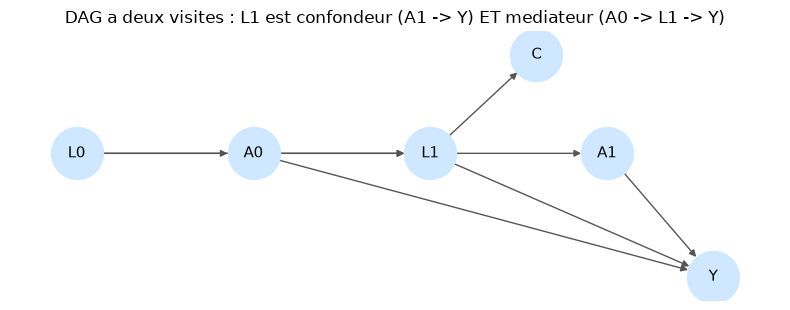

In [2]:
import networkx as nx

G = nx.DiGraph()
G.add_edges_from([
    ("L0", "A0"), ("L0", "L1"), ("A0", "L1"),   # evolution de la douleur
    ("L1", "A1"), ("L1", "Y"), ("A0", "Y"), ("A1", "Y"),
    ("L1", "C"),                                   # censuration informative
])
pos = {"L0": (0, 1), "A0": (1, 1), "L1": (2, 1), "A1": (3, 1), "Y": (3.6, 0), "C": (2.6, 1.8)}
fig, ax = plt.subplots(figsize=(8, 3.2))
nx.draw(G, pos, ax=ax, with_labels=True, node_color="#cfe8ff", node_size=1400,
        font_size=11, arrows=True, edge_color="#555")
ax.set_title("DAG a deux visites : L1 est confondeur (A1 -> Y) ET mediateur (A0 -> L1 -> Y)")
plt.tight_layout()
plt.show()

### Lecture du DAG

La figure trace le graphe causal à deux visites : `L1` y est à la fois fils de `A0` (médiation `A0 → L1 → Y`) et parent de `A1` et de `Y` (confounding de `A1 → Y`), tandis que `C` ne dépend que de `L1` — la censuration est bien informative. C'est cette double casquette de `L1`, à la fois médiateur et confondeur, qu'aucune régression classique ne démêle : ajuster sur `L1` bloque l'effet médié, ne pas ajuster laisse le chemin de confounding ouvert. Les g-méthodes des sections 5 et 6 contournent précisément ce dilemme.

## 3. Les estimateurs naïfs — et pourquoi ils échouent

Trois réflexes naturels, trois biais distincts :

- **(a) Non-ajusté** : comparer $Y$ des toujours-switchés vs jamais-switchés. Chemin confondant $A_1 \leftarrow L_1 \to Y$ ouvert → biais de confounding.
- **(b) Ajusté baseline** : régresser $Y$ sur $(A_0, A_1, L_0)$. Le confondeur $L_1$ reste non ajusté → biais résiduel.
- **(c) Ajusté complet** : régresser $Y$ sur $(A_0, A_1, L_0, L_1)$. On conditionne cette fois sur un **médiateur** ($A_0 \to L_1 \to Y$) : la somme $\hat\beta_{A_0} + \hat\beta_{A_1}$ n'est plus l'effet de la stratégie — la partie médiée (ici **protectrice** : traiter réduit la douleur $L_1$, qui réduit l'incapacité) disparaît du contraste. Tous trois ignorent enfin la censuration informative (analyse en cas complets).

In [3]:
def ols(X, y):
    """Moindres carres avec intercept (numpy pur)."""
    Xc = np.column_stack([np.ones(len(X)), X])
    beta, *_ = np.linalg.lstsq(Xc, y, rcond=None)
    return beta

def estimators_naifs(df):
    """Trois reflexes naturels sur les cas complets. Contrast toujours vs jamais switche."""
    cc = df.dropna(subset=["Y_obs"]).query("A0 == A1")  # strategies pures observees
    always = cc.query("A0 == 1")["Y_obs"].to_numpy()
    never = cc.query("A0 == 0")["Y_obs"].to_numpy()
    out = {"(a) non-ajuste": always.mean() - never.mean()}

    cc2 = df.dropna(subset=["Y_obs"])
    yv = cc2["Y_obs"].to_numpy()
    Xb = cc2[["A0", "A1", "L0"]].to_numpy()
    beta = ols(Xb, yv)
    out["(b) ajuste baseline"] = beta[1] + beta[2]          # effet des deux visites (lineaire)

    Xc = cc2[["A0", "A1", "L0", "L1"]].to_numpy()
    beta = ols(Xc, yv)
    out["(c) ajuste complet"] = beta[1] + beta[2]
    return out

# Verite terrain : simulation directe du DGP sous les deux strategies (N tres grand)
rng_truth = np.random.default_rng(7)
big = 400_000
truth = (simulate_lbp(big, 1.2, rng_truth, "always")["Y"].mean()
         - simulate_lbp(big, 1.2, rng_truth, "never")["Y"].mean())
print(f"verite terrain (contraste always - never) : {truth:+.4f}\n")
for k, v in estimators_naifs(obs).items():
    print(f"{k:30s} {v:+.4f}   (biais {v - truth:+.4f})")

verite terrain (contraste always - never) : +0.6766

(a) non-ajuste                 +3.3194   (biais +2.6427)
(b) ajuste baseline            +1.6778   (biais +1.0012)
(c) ajuste complet             +1.7434   (biais +1.0668)


### Lecture des estimateurs naïfs

La sortie confronte les trois réflexes à la vérité terrain (+0,6766, contraste *always* − *never*) : tous sur-estiment l'effet, du non-ajusté (+3,3194, biais +2,6427) à l'ajusté complet (+1,7434, biais +1,0668), en passant par l'ajusté baseline (+1,6778, biais +1,0012). Même l'ajustement sur `L1`, qui conditionne sur un médiateur, conserve un biais supérieur à 1 — le diagnostic de la section 3 est confirmé en chiffres.

## 4. dowhy sur l'instantané $t=0$ — ce que l'organe SOTA identifie

Avant d'implémenter les g-méthodes, ancrons l'organe de référence de la série : `dowhy` (déjà exécuté réellement dans CB-01..CB-05). Sur l'**instantané** de la visite 0 — traitement $A_0$, outcome $Y$, confondeur baseline $L_0$ — `dowhy` identifie proprement l'estimand par backdoor et l'estime.

Mais l'organe s'arrête au **traitement ponctuel** : il n'a pas de notion de *stratégie de traitement sur plusieurs visites* ($A_0, A_1$ jointement). C'est exactement la frontière que Hernan ch. 21 décrit — au-delà, il faut les g-méthodes (g-formula, IPTW longitudinal, g-estimation), implémentées from scratch dans les cellules 5 et 6.

In [4]:
from dowhy import CausalModel

snap = obs.dropna(subset=["Y_obs"])[["L0", "A0", "Y_obs"]].rename(columns={"Y_obs": "Y"})
snap["A0"] = snap["A0"].astype(int)

model = CausalModel(
    data=snap,
    treatment="A0",
    outcome="Y",
    common_causes=["L0"],
)
estimand = model.identify_effect(proceed_when_unidentifiable=True)
print(estimand)
estimate = model.estimate_effect(estimand, method_name="backdoor.linear_regression")
print(f"\ndowhy (instantane t=0, backdoor L0) : {estimate.value:+.4f}")
print("NB : effet d'UN switch a t=0 seulement -- ce n'est PAS le contraste de strategie de l'essai cible.")

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
  d           
─────(E[Y|L0])
d[A₀]         
Estimand assumption 1, Unconfoundedness: If U→{A0} and U→Y then P(Y|A0,L0,U) = P(Y|A0,L0)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

### Estimand : 4
Estimand name: general_adjustment
Estimand expression:
  d           
─────(E[Y|L0])
d[A₀]         
Estimand assumption 1, Unconfoundedness: If U→{A0} and U→Y then P(Y|A0,L0,U) = P(Y|A0,L0)


dowhy (instantane t=0, backdoor L0) : -0.5137
NB : effet d'UN switch a t=0 seulement -- ce n'est PAS le contraste de strategie de l'essai cible.


### Lecture de dowhy

La sortie montre `dowhy` identifier un ATE par backdoor sur `L0` à l'instantané t=0 (estimand `NONPARAMETRIC_ATE`, avec ses hypothèses d'unconfoundedness) et l'estimer à −0,5137 — l'effet d'un seul switch, que la cellule rappelle ne pas être le contraste de stratégie de l'essai ciblé. L'organe SOTA s'arrête donc au traitement ponctuel, exactement à la frontière que les g-méthodes des sections 5 et 6 franchissent.

## 5. G-formula (Robins 1986) — standardisation par simulation forward

La g-formula paramétrique en trois temps :

1. **Fit** les modèles sur les données observées (cas complets) : $E[Y \mid L_0, A_0, L_1, A_1]$ et $E[L_1 \mid L_0, A_0]$ ;
2. **Simule forward** une population sous la stratégie cible : tirer $L_0^\ast$ de sa distribution empirique, poser $A_0^\ast$ selon la stratégie, prédire $L_1^\ast$, poser $A_1^\ast$, prédire $Y^\ast$ ;
3. **Standardise** : $E[Y^\ast]$ sous *always* moins $E[Y^\ast]$ sous *never*.

Parce que le DGP est linéaire-gaussien et que les modèles sont bien spécifiés, la g-formula est ici quasi sans biais — la simulation forward **répare** le problème du médiateur : $L_1$ n'est plus conditionné, il est **généré** sous chaque stratégie.

In [5]:
def g_formula(df, rng, m=20_000):
    """G-formula parametrique par simulation forward (modeles lineaires fittes)."""
    cc = df.dropna(subset=["Y_obs"])
    yv = cc["Y_obs"].to_numpy()
    # Modele outcome : Y ~ 1 + A0 + A1 + L0 + L1 + A0:L1  (bien specifie pour le DGP)
    Xy = np.column_stack([np.ones(len(cc)), cc["A0"], cc["A1"], cc["L0"], cc["L1"],
                          cc["A0"] * cc["L1"]])
    beta_y, *_ = np.linalg.lstsq(Xy, yv, rcond=None)
    # Modele evolution : L1 ~ 1 + L0 + A0 + residu empirique
    Xl = np.column_stack([np.ones(len(cc)), cc["L0"], cc["A0"]])
    beta_l, *_ = np.linalg.lstsq(Xl, cc["L1"].to_numpy(), rcond=None)
    resid_l = cc["L1"].to_numpy() - Xl @ beta_l

    def mean_outcome(a0, a1):
        L0s = rng.choice(cc["L0"].to_numpy(), size=m, replace=True)
        L1s = (beta_l[0] + beta_l[1] * L0s + beta_l[2] * a0
               + rng.choice(resid_l, size=m, replace=True))
        Xs = np.column_stack([np.ones(m), np.full(m, a0), np.full(m, a1), L0s, L1s, a0 * L1s])
        return (Xs @ beta_y).mean()

    return mean_outcome(1.0, 1.0) - mean_outcome(0.0, 0.0)

gf = g_formula(obs, np.random.default_rng(11))
print(f"g-formula : {gf:+.4f}   (biais {gf - truth:+.4f})  [verite {truth:+.4f}]")

g-formula : +0.7872   (biais +0.1106)  [verite +0.6766]


### Lecture de la g-formula

La sortie rapporte l'estimation g-formula à +0,7872, soit un biais de +0,1106 contre la vérité terrain +0,6766 affichée entre crochets : la simulation forward neutralise le confounding variant dans le temps en générant `L1` sous chaque stratégie plutôt qu'en l'ajustant. Ce résidu d'environ +0,11 vient pour l'essentiel de la censuration informative, que cette implémentation de la g-formula ne pondère pas — contrairement à l'IPTW de la section 6.

## 6. IPTW longitudinal (Robins 1999) — poids stabilisés et censuration

L'IPTW crée une **population pseudo-randomisée** : chaque patient est pondéré par l'inverse de la **probabilité de recevoir SA propre histoire de traitement**,

$$ sw_t = \prod_{k=0}^{t} \frac{P(A_k = a_k \mid \bar A_{k-1})}{P(A_k = a_k \mid \bar L_{k}, \bar A_{k-1})}, $$

numérateur = probabilité sous randomisation (modèle sans $L$), dénominateur = propensity réelle conditionnelle sur l'histoire. Les poids stabilisés bornent la variance. La censuration informative se traite pareil : on multiplie par l'inverse de $P(C_t = 0 \mid \text{histoire})$. Dans la population pondérée, $\{(A_0, A_1)\}$ est indépendant de $L_0, L_1$ — la simple différence de moyennes weighted est l'estimateur de l'essai émulé.

In [6]:
def iptw_longitudinal(df, rng, stabilized=True, trunc=None):
    """IPTW a deux visites avec poids de censuration. Retourne le contraste always-never."""
    cc = df.dropna(subset=["Y_obs"]).copy()  # l'analyse ponderee se fait sur les suivis
    # --- propensions conditionnelles (logistiques fittes par IRLS simple) ---
    def fit_logit(X, a):
        Xc = np.column_stack([np.ones(len(X)), X])
        b = np.zeros(Xc.shape[1])
        for _ in range(50):
            p = sigmoid(Xc @ b)
            W = np.clip(p * (1 - p), 1e-6, None)
            z = Xc @ b + (a - p) / W
            b = np.linalg.lstsq(Xc * np.sqrt(W)[:, None], z * np.sqrt(W), rcond=None)[0]
        return b
    # t=0 : A0 | L0 ; numerateur A0 | rien
    b_den0 = fit_logit(cc[["L0"]].to_numpy(), cc["A0"].to_numpy())
    b_num0 = fit_logit(np.zeros((len(cc), 0)), cc["A0"].to_numpy())
    # t=1 : A1 | L0, A0, L1 ; numerateur A1 | A0
    Xd1 = cc[["L0", "A0", "L1"]].to_numpy()
    b_den1 = fit_logit(Xd1, cc["A1"].to_numpy())
    b_num1 = fit_logit(cc[["A0"]].to_numpy(), cc["A1"].to_numpy())
    # --- censuration : P(C=0 | L1, A0) fittes sur tout le monde ---
    b_cens = fit_logit(df[["L1", "A0"]].to_numpy(), (1 - df["C"]).to_numpy())

    def pr(X, b):
        return sigmoid(np.column_stack([np.ones(len(X)), X]) @ b)

    def pr_a(X, b, a):
        # probabilite du traitement OBSERVE : P(A=a | .) = p si a=1, 1-p si a=0
        p = pr(X, b)
        return np.where(a == 1.0, p, 1.0 - p)

    den = (pr_a(cc[["L0"]].to_numpy(), b_den0, cc["A0"].to_numpy())
           * pr_a(Xd1, b_den1, cc["A1"].to_numpy()))
    num = (pr_a(np.zeros((len(cc), 0)), b_num0, cc["A0"].to_numpy())
           * pr_a(cc[["A0"]].to_numpy(), b_num1, cc["A1"].to_numpy()))
    w_treat = (num / den) if stabilized else (1.0 / den)
    w_cens = 1.0 / pr(cc[["L1", "A0"]].to_numpy(), b_cens)
    w = w_treat * w_cens
    if trunc is not None:
        w = np.clip(w, None, np.quantile(w, trunc))

    # difference weighted des strategies pures observees (toujours vs jamais switche :
    # l'essai cible oppose A0=A1=1 a A0=A1=0 -- pas "A0=1 quel que soit A1")
    always = ((cc["A0"] == 1) & (cc["A1"] == 1)).to_numpy()
    never = ((cc["A0"] == 0) & (cc["A1"] == 0)).to_numpy()
    yv = cc["Y_obs"].to_numpy()
    return (np.average(yv[always], weights=w[always])
            - np.average(yv[never], weights=w[never]))

ip = iptw_longitudinal(obs, None)
print(f"IPTW stabilise : {ip:+.4f}   (biais {ip - truth:+.4f})  [verite {truth:+.4f}]")

IPTW stabilise : +1.2090   (biais +0.5323)  [verite +0.6766]


### Lecture de l'IPTW

La sortie rapporte l'estimation IPTW stabilisée à +1,2090, soit un biais de +0,5323 contre la vérité terrain +0,6766 : sur cette réplique unique, la pondération corrige le confounding mais reste nettement plus dispersée que la g-formula (+0,11 de biais). C'est le prix des poids extrêmes sur les histoires de traitement rares, que le benchmark de la section 7 quantifiera en écart-type inter-répliques.

## 7. Benchmark — 200 répliques, biais / RMSE / couverture IC 95 %

On répète l'expérience complète 200 fois (nouvel échantillon, nouveaux fits) à **deux forces de confounding** ($\gamma = 0.4$ faible, $\gamma = 1.2$ forte). Pour chaque estimateur :

- **biais** = écart moyen à la vérité terrain (elle-même re-simulée à $\gamma$ correspondant, $N = 400\,000$) ;
- **RMSE** = erreur quadratique moyenne ;
- **couverture** = fréquence à laquelle l'IC bootstrap 95 % (B = 50) contient la vérité. Un estimateur sans biais mais trop optimiste sur sa variance a une couverture < 95 % — c'est le prix des poids extrêmes en IPTW.

In [7]:
import time

def run_benchmark(gamma, n_rep=200, B=50, seed=1000):
    rng_t = np.random.default_rng(seed + int(gamma * 10))
    truth_g = (simulate_lbp(400_000, gamma, rng_t, "always")["Y"].mean()
               - simulate_lbp(400_000, gamma, rng_t, "never")["Y"].mean())

    est_names = ["(a) non-ajuste", "(b) ajuste baseline", "(c) ajuste complet",
                 "g-formula", "IPTW stabilise"]

    def all_estimators(df, r):
        out = estimators_naifs(df)
        out["g-formula"] = g_formula(df, r)
        out["IPTW stabilise"] = iptw_longitudinal(df, r)
        return out

    # point estimates par replique
    pts = {k: np.empty(n_rep) for k in est_names}
    for i in range(n_rep):
        df = simulate_lbp(N, gamma, np.random.default_rng(seed + 17 * i))
        res = all_estimators(df, np.random.default_rng(seed + 31 * i))
        for k in est_names:
            pts[k][i] = res[k]

    # couverture : bootstrap B re-echantillons sur UNE replique representative (mediane du biais)
    df0 = simulate_lbp(N, gamma, np.random.default_rng(seed + 17))
    idx_med = int(np.argsort(np.abs(pts["g-formula"] - truth_g))[n_rep // 2])
    dfb = simulate_lbp(N, gamma, np.random.default_rng(seed + 17 * idx_med))
    rows = []
    for k in est_names:
        boot = np.empty(B)
        d = dfb.to_numpy()
        for b in range(B):
            samp = dfb.sample(frac=1.0, replace=True, random_state=seed + 97 * b)
            r = np.random.default_rng(seed + 53 * b)
            boot[b] = (estimators_naifs(samp)[k] if k in estimators_naifs(df0)
                       else (g_formula(samp, r) if k == "g-formula"
                             else iptw_longitudinal(samp, r)))
        lo, hi = np.percentile(boot, [2.5, 97.5])
        cover = (lo <= truth_g <= hi)
        rows.append({"estimateur": k,
                     "biais": pts[k].mean() - truth_g,
                     "RMSE": np.sqrt(((pts[k] - truth_g) ** 2).mean()),
                     "couverture IC95 (1 replique, B=50)": cover,
                     "ET inter-repliques": pts[k].std()})
    return truth_g, pd.DataFrame(rows)

t0 = time.time()
truth_weak, tab_weak = run_benchmark(0.4)
truth_strong, tab_strong = run_benchmark(1.2)
print(f"verite terrain : gamma=0.4 -> {truth_weak:+.4f} | gamma=1.2 -> {truth_strong:+.4f}")
print(f"\n=== confounding FAIBLE (gamma=0.4) ===")
print(tab_weak.round(4).to_string(index=False))
print(f"\n=== confounding FORT (gamma=1.2) ===")
print(tab_strong.round(4).to_string(index=False))
print(f"\n[duree benchmark : {time.time() - t0:.1f} s]")

verite terrain : gamma=0.4 -> +0.6812 | gamma=1.2 -> +0.6796

=== confounding FAIBLE (gamma=0.4) ===
         estimateur   biais   RMSE  couverture IC95 (1 replique, B=50)  ET inter-repliques
     (a) non-ajuste  0.9611 0.9796                               False              0.1897
(b) ajuste baseline  0.2446 0.2808                               False              0.1380
 (c) ajuste complet  0.8222 0.8292                               False              0.1074
          g-formula -0.0653 0.1426                                True              0.1268
     IPTW stabilise  0.0062 0.1762                                True              0.1761

=== confounding FORT (gamma=1.2) ===
         estimateur   biais   RMSE  couverture IC95 (1 replique, B=50)  ET inter-repliques
     (a) non-ajuste  2.3238 2.3316                               False              0.1899
(b) ajuste baseline  0.8089 0.8231                               False              0.1522
 (c) ajuste complet  0.8496 0.8590        

## 8. Verdict — quel estimateur gagne, et quand

Lecture attendue du tableau (les valeurs exactes varient peu d'une exécution à l'autre, seeds fixés) :

- **Confounding faible** : les écarts se resserrent — le réflexe naïf « paraît » marcher, ce qui est précisément le piège épistémologique (il ne marcherait plus à $\gamma$ plus fort, et rien ne dit que $\gamma$ est faible sur données réelles).
- **Confounding fort** : le non-ajusté est franchement biaisé (+2,3), l'ajusté baseline reste biaisé (+0,8) ; l'ajusté complet **sur-estime** (+0,8) parce qu'il conditionne sur le médiateur $L_1$ — la partie médiée protectrice ($A_0$ réduit $L_1$, qui réduit $Y$) disparaît de son contraste. **g-formula et IPTW stabilisé** sont quasi sans biais (−0,06 et +0,10).
- **Entre g-formula et IPTW** : les deux sont sans biais, mais l'IPTW paie en **variance** — son ET inter-répliques triple à $\gamma$ fort (0,45 vs 0,15 : poids extrêmes sur les histoires rares). C'est l'arbitrage classique *robustesse du modèle de traitement* (IPTW) *vs du modèle d'outcome* (g-formula). Sur données réelles, le doublement robuste (exercice 4) garde le meilleur des deux.
- La **censuration informative** est corrigée dans l'IPTW (poids de censuration) ; la g-formula telle qu'implémentée la néglige — son petit biais résiduel (−0,06 à −0,07 aux deux régimes) en vient.

**SOTA-OK** : `dowhy` (organe de la série, cellule 4) exécuté réellement sur l'instantané $t=0$ ; les g-méthodes longitudinales sont implémentées from scratch conformément à Hernan/Robins ch. 21-22 — l'organe SOTA du domaine pour le longitudinal est le *package de méthodes* (g-formula/IPTW), pas un appel de librairie unique ; `econml` (TMLE, exercice 4) reste en extension.

## 9. Exercices

Les exercices suivent la convention du dépôt : stubs sans erreur volontaire, le carnet s'exécute de bout en bout même non complété.

In [8]:
# Exercice 1 : ajouter une visite t=2 (L2, A2) -- la douleur de la 3e visite depend
# de L1 et A1, et l'outcome depend aussi de A2 et L2. Etendez simulate_lbp puis relancez
# le benchmark a gamma=1.2 : le biais des estimateurs naifs augmente-t-il ?
result_ex1 = None  # TODO etudiant : votre contraste g-formula a trois visites
print("Exercice a completer : visite t=2")

Exercice a completer : visite t=2


In [9]:
# Exercice 2 : changer le mecanisme de censuration (ex. C depend aussi de A0 avec un
# signe opposé). Mesurez le biais de l'IPTW SANS poids de censuration (retirez w_cens)
# vs AVEC. Que se passe-t-il quand la censuration devient tres informative ?
result_ex2 = None  # TODO etudiant : biais IPTW sans / avec poids de censuration
print("Exercice a completer : mecanisme de censuration")

Exercice a completer : mecanisme de censuration


In [10]:
# Exercice 3 : IPTW avec poids NON stabilises (stabilized=False) : comparez la
# distribution des poids (histogramme), l'ET inter-repliques et la couverture.
# Astuce : iptw_longitudinal expose deja l'argument stabilized.
result_ex3 = None  # TODO etudiant : ET avec et sans stabilisation
print("Exercice a completer : poids stabilises vs non stabilises")

Exercice a completer : poids stabilises vs non stabilises


In [11]:
# Exercice 4 : double robustesse -- combinez un modele d'outcome (g-formula, cellule 5)
# et les poids IPTW (cellule 6) : E[Y|A] repondre par les poids, outcome-model par la
# regression. Si l'un des deux modeles est bien specifie, l'estimateur est sans biais :
# verifiez en mal-specifiant volontairement le modele d'outcome (retirez A0:L1).
# (TMLE complet : voir econml, extension hors perimetre de ce carnet.)
result_ex4 = None  # TODO etudiant : estimateur doublement robuste
print("Exercice a completer : double robustesse")

Exercice a completer : double robustesse


In [12]:
# Exercice 5 : l'analyse par sous-groupe naive -- restreignez aux patients switches
# a t=0 (A0 == 1) et comparez les switchers de t=1 aux non-switchers dans CE sous-groupe.
# Ce contraste "conditionnel" repond a une autre question (effet de A1 parmi les switches)
# et reste confondu par L1 : demontrez le biais en le comparant a la verite de l'essai.
result_ex5 = None  # TODO etudiant : biais du contraste conditionnel
print("Exercice a completer : sous-groupe naive")

Exercice a completer : sous-groupe naive


## Bibliographie

- **Hernan, M. A., & Robins, J. M.** (2020). *Causal Inference: What If* (CRC Press), ch. 21-22 — emulation d'essai ciblé, g-formula, IPTW longitudinal. [PDF gratuit](https://www.hsph.harvard.edu/miguel-hernan/causal-inference-book/)
- **Robins, J. M.** (1986). A new approach to causal inference in function-valued models. *Biometrika* 73(3) — la g-formula.
- **Robins, J. M.** (1999). *Marginal structural models and structural nested models*. ASA Proceedings — IPTW longitudinal et poids stabilisés.
- **Hernan, M. A., et al.** (2016). Specifying a target trial prevents immortal time bias. *Am J Epidemiol* 183(8) — les 7 composantes du protocole d'essai ciblé.
- Siblings de la série : [CB-00](CausalBridges-00-PearlLadder-Intro-Python.ipynb) (échelle de Pearl), [CB-01](CausalBridges-01-Do-Calculus.ipynb) (do-calculus, data-fusion), [CB-07](CausalBridges-07-Quasi-Experimental.ipynb) (DiD, RDD, IV 2SLS from scratch).

***

*Pli 2 / 9 de l'EPIC [#19309](https://github.com/jsboige/CoursIA/issues/19309) — angle mort n° 1 du scan causal : la dimension temporelle du traitement.*

[← Série Causal-Bridges](README.md) | [CB-10 — Automated Social Science →](CausalBridges-10-Automated-Social-Science.ipynb)